# Baselines: median and Ridge

The median asks how far a constant price gets us. Ridge adds a regularised linear relationship between property attributes and price. Both use the same chronological splits.

In [1]:
import os
from pathlib import Path

ROOT = Path.cwd()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
SMOKE = os.environ.get("HDB_SMOKE") == "1"
DATA = ROOT / ("tests/fixtures/transactions.csv" if SMOKE else "data/raw/resale.csv")
RUNS = Path(os.environ.get("HDB_RUN_ROOT", str(ROOT / "artifacts")))

import matplotlib.pyplot as plt
from IPython.display import display

print(f"Data: {DATA.name}; mode: {'synthetic smoke' if SMOKE else 'frozen snapshot'}")

Data: resale.csv; mode: frozen snapshot


In [2]:
from hdb_resale.data import load_data
from hdb_resale.experiment import (
    compare_runs,
    evaluate_experiment,
    load_bundle,
    predict,
    train_experiment,
)
from hdb_resale.plots import plot_comparison

for name in ("median", "ridge"):
    run = RUNS / name
    if not (run / "metadata.json").exists():
        train_experiment(DATA, name, run)
    evaluate_experiment(run, DATA)

comparison = compare_runs([RUNS / "median", RUNS / "ridge"])
comparison

,model,validation_mae_sgd,fit_seconds,test_count,test_mae_sgd,test_rmse_sgd,test_r2
0,ridge,54324.963603,8.505756,5414,64631.342780,85068.028315,0.814390
1,median,183801.932362,4.394507,5414,204699.580436,267294.318962,-0.832514


## Interpretation

Configuration is fixed: training-set median; Ridge with alpha=1, scaled numeric features, and one-hot categorical encoding. There is no test-driven tuning. The comparison is ordered by validation MAE, not test performance.

Linear extrapolation in transaction month can help under rising prices, but assumes trends persist. Treat subgroup errors and later-period degradation as limitations.

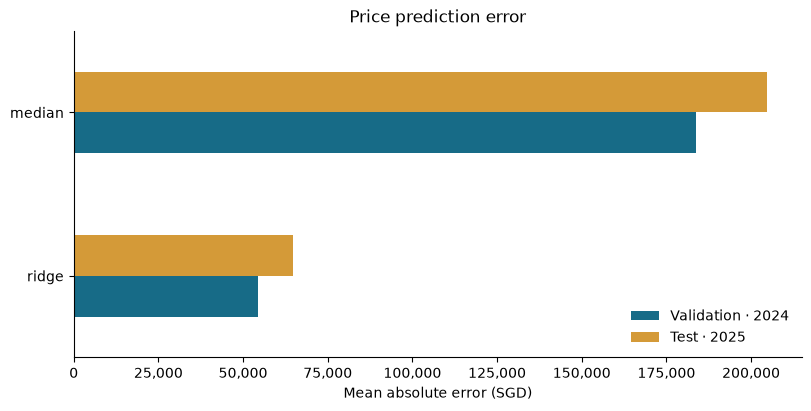

In [3]:
figure = plot_comparison(comparison)
display(figure)
plt.close(figure)

In [4]:
sample = load_data(DATA).tail(3).drop(columns="resale_price")
sample.assign(predicted_price_sgd=predict(load_bundle(RUNS / "ridge"), sample))

,month,town,flat_type,block,street_name,storey_range,floor_area_sqm,flat_model,lease_commence_date,remaining_lease,predicted_price_sgd
202396,2025-01-01,YISHUN,EXECUTIVE,836,YISHUN ST 81,01 TO 03,146.0,Maisonette,1988,62 years 02 months,777039.826761
202397,2025-02-01,YISHUN,EXECUTIVE,824,YISHUN ST 81,01 TO 03,145.0,Apartment,1987,61 years 10 months,753144.677674
202398,2025-02-01,YISHUN,EXECUTIVE,826,YISHUN ST 81,10 TO 12,146.0,Maisonette,1988,62 years,815895.566337


## Test error analysis

The diagonal marks perfect predictions; darker hexagons contain more transactions. Residuals are predicted minus actual SGD, so negative values mean underprediction. Read subgroup MAE with its count: small groups give unstable estimates. These final diagnostics describe limitations and do not trigger test-driven retuning.

Test diagnostics: median


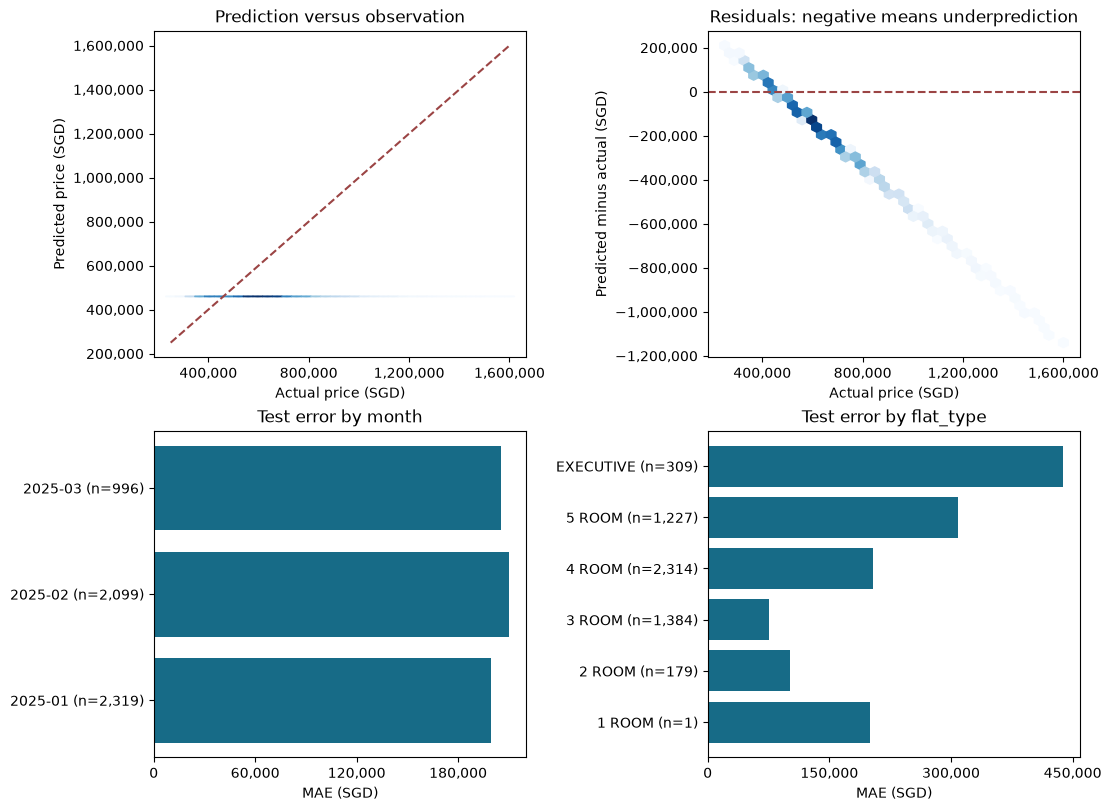

Test diagnostics: ridge


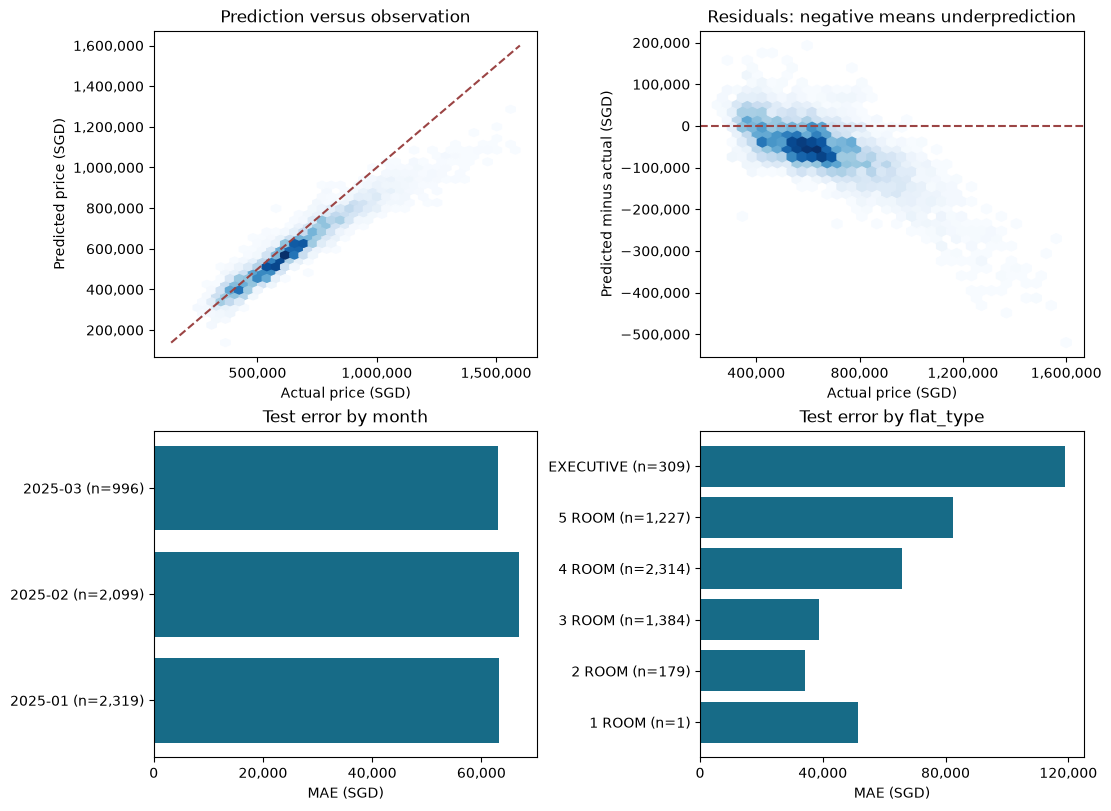

In [5]:
import pandas as pd

from hdb_resale.plots import plot_diagnostics

diagnostic_runs = [RUNS / name for name in ("median", "ridge")]
for diagnostic_run in diagnostic_runs:
    predictions = pd.read_csv(diagnostic_run / "test_predictions.csv")
    groups = pd.read_csv(diagnostic_run / "test_groups.csv")
    print(f"Test diagnostics: {diagnostic_run.name}")
    figure = plot_diagnostics(predictions, groups)
    display(figure)
    plt.close(figure)

## Reproduce without this notebook

Use the `train`, `evaluate`, and `predict` commands in the README. Saved bundles include fitted preprocessing and feature order; prediction does not need the observed price.

The sample above illustrates the interface, not an independent accuracy test. See the full test metrics for performance.